In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("data.csv", encoding="cp1252")

print("Dataset loaded successfully!")
print(data.head())

C:\Users\DELL\AppData\Local\Temp\ipykernel_15132\3917883548.py:1: DtypeWarning: Columns (0: stn_code) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("data.csv", encoding="cp1252")


Dataset loaded successfully!
  stn_code       sampling_date           state   location agency  \
0    150.0  February - M021990  Andhra Pradesh  Hyderabad    NaN   
1    151.0  February - M021990  Andhra Pradesh  Hyderabad    NaN   
2    152.0  February - M021990  Andhra Pradesh  Hyderabad    NaN   
3    150.0     March - M031990  Andhra Pradesh  Hyderabad    NaN   
4    151.0     March - M031990  Andhra Pradesh  Hyderabad    NaN   

                                 type  so2   no2  rspm  spm  \
0  Residential, Rural and other Areas  4.8  17.4   NaN  NaN   
1                     Industrial Area  3.1   7.0   NaN  NaN   
2  Residential, Rural and other Areas  6.2  28.5   NaN  NaN   
3  Residential, Rural and other Areas  6.3  14.7   NaN  NaN   
4                     Industrial Area  4.7   7.5   NaN  NaN   

  location_monitoring_station  pm2_5        date  
0                         NaN    NaN  1990-02-01  
1                         NaN    NaN  1990-02-01  
2                         NaN 

In [3]:
print("Dataset Shape:", data.shape)

print("\nColumn Names:")
print(data.columns)

print("\nDataset Information:")
data.info()

print("\nStatistical Summary:")
print(data.describe())

Dataset Shape: (435742, 13)

Column Names:
Index(['stn_code', 'sampling_date', 'state', 'location', 'agency', 'type',
       'so2', 'no2', 'rspm', 'spm', 'location_monitoring_station', 'pm2_5',
       'date'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 435742 entries, 0 to 435741
Data columns (total 13 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   stn_code                     291665 non-null  object 
 1   sampling_date                435739 non-null  str    
 2   state                        435742 non-null  str    
 3   location                     435739 non-null  str    
 4   agency                       286261 non-null  str    
 5   type                         430349 non-null  str    
 6   so2                          401096 non-null  float64
 7   no2                          419509 non-null  float64
 8   rspm                         395520 non-null  float64


In [4]:
print("Missing Values:")
print(data.isnull().sum())

print("\nDuplicate Records:")
print(data.duplicated().sum())

Missing Values:
stn_code                       144077
sampling_date                       3
state                               0
location                            3
agency                         149481
type                             5393
so2                             34646
no2                             16233
rspm                            40222
spm                            237387
location_monitoring_station     27491
pm2_5                          426428
date                                7
dtype: int64

Duplicate Records:
674


In [5]:
# Correct state names
if "state" in data.columns:
    data["state"] = data["state"].replace({
        "Uttaranchal": "Uttarakhand"
    })

# Correct Jamshedpur state
if "location" in data.columns and "state" in data.columns:
    data.loc[
        data["location"] == "Jamshedpur", "state"
    ] = "Jharkhand"

# Standardize area types
if "type" in data.columns:
    data["type"] = data["type"].replace({
        "Residential": "R",
        "Residential and others": "RO",
        "Residential, Rural and other Areas": "RRO",
        "Industrial Area": "I",
        "Industrial Areas": "I",
        "Industrial": "I",
        "Sensitive Area": "S",
        "Sensitive Areas": "S",
        "Sensitive": "S"
    })

print("Names standardized!")

Names standardized!


In [6]:
data = data.drop_duplicates()

print("Duplicates removed!")
print("New dataset shape:", data.shape)

Duplicates removed!
New dataset shape: (435068, 13)


In [7]:
# Pollutant columns available in this dataset
pollutants = ["so2", "no2", "rspm", "spm", "pm2_5"]

# Keep only columns that actually exist
pollutants = [col for col in pollutants if col in data.columns]

# Convert pollutant values into numbers
for col in pollutants:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Fill missing values with column average
for col in pollutants:
    data[col] = data[col].fillna(data[col].mean())

print("Missing pollutant values handled!")
print(data[pollutants].isnull().sum())

Missing pollutant values handled!
so2      0
no2      0
rspm     0
spm      0
pm2_5    0
dtype: int64


In [8]:
# Convert date column if available
if "date" in data.columns:
    data["date"] = pd.to_datetime(
        data["date"], errors="coerce", dayfirst=True
    )

# Convert time column if available
if "time" in data.columns:
    data["time"] = pd.to_datetime(
        data["time"], errors="coerce"
    ).dt.time

print("Date and time conversion completed!")

Date and time conversion completed!


In [9]:
print("Average Pollutant Levels:")

print(data[pollutants].mean())

Average Pollutant Levels:
so2       10.830468
no2       25.823296
rspm     108.871711
spm      220.774796
pm2_5     40.791467
dtype: float64


Average pollution by state:
                         so2        no2        rspm         spm      pm2_5
state                                                                     
Andhra Pradesh      7.399760  21.854149   79.580221  211.571954  40.791467
Arunachal Pradesh   5.134453  10.897323   76.987463  220.774796  40.791467
Assam               6.751181  14.837080   93.940088  200.265596  40.791467
Bihar              16.669379  35.319448  118.253498  270.893321  40.791467
Chandigarh          6.601568  19.411165   97.123829  212.255021  40.791467


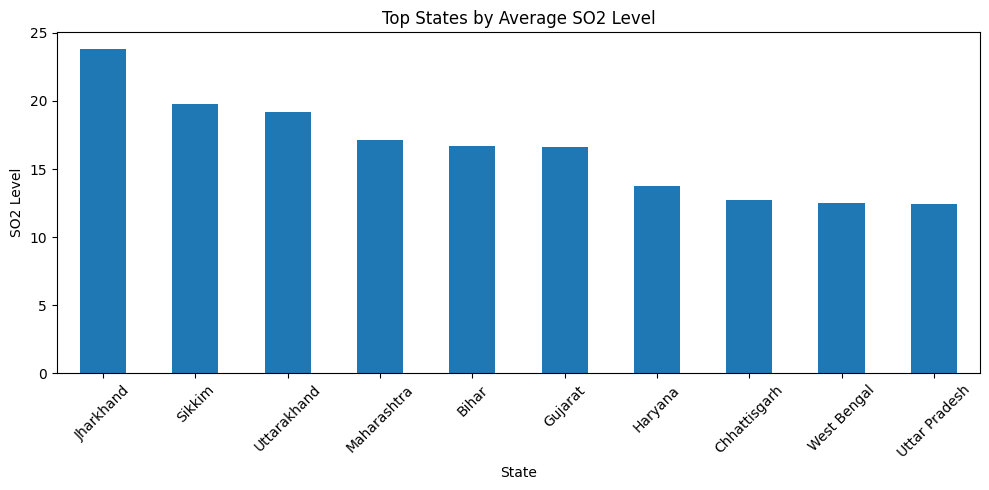

In [10]:
if "state" in data.columns:
    state_data = data.groupby("state")[pollutants].mean()

    print("Average pollution by state:")
    print(state_data.head())

    state_data["so2"].sort_values(
        ascending=False
    ).head(10).plot(kind="bar", figsize=(10, 5))

    plt.title("Top States by Average SO2 Level")
    plt.xlabel("State")
    plt.ylabel("SO2 Level")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

             so2        no2        rspm         spm      pm2_5
type                                                          
I      13.218263  29.321948  120.634045  230.827184  40.850151
R      13.836224  21.335896  108.871711  272.668663  40.791467
RIRUO  10.912577  31.779908  103.617331  220.774796  39.474997
RO     10.353213  25.414417  102.983897  214.538020  40.791467
RRO     9.275303  23.495255  102.857164  215.896689  40.752462
S       6.631723  20.270393  100.366989  227.169936  40.791467


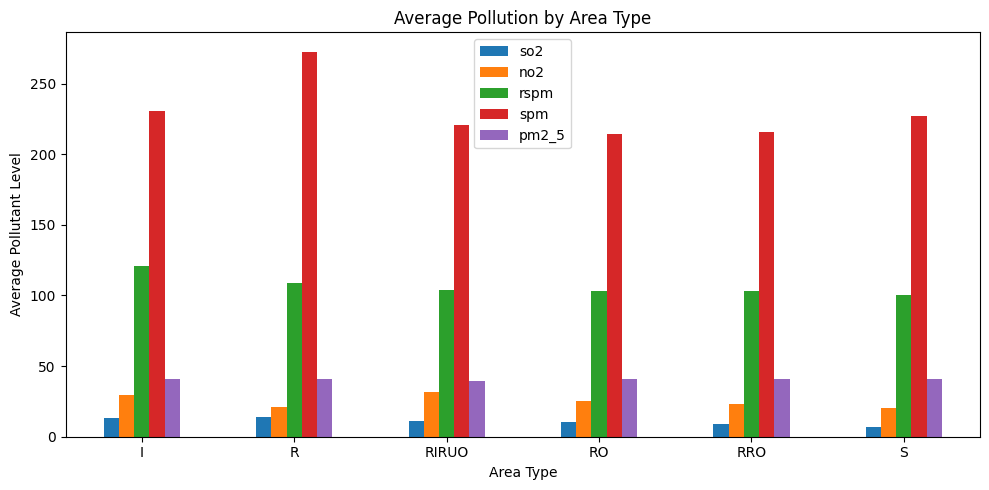

In [11]:
if "type" in data.columns:
    type_data = data.groupby("type")[pollutants].mean()

    print(type_data)

    type_data.plot(kind="bar", figsize=(10, 5))

    plt.title("Average Pollution by Area Type")
    plt.xlabel("Area Type")
    plt.ylabel("Average Pollutant Level")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

                                 so2        no2        rspm         spm  \
state          location                                                   
Andhra Pradesh Ananthapur   4.651235  11.188272   77.969136  220.774796   
               Chittoor     4.561937  10.730856   54.888225  212.342829   
               Eluru        8.587151  23.859466  103.920000  220.774796   
               Guntur       4.280653  16.218320   81.413151  216.988703   
               Hyderabad    5.850898  26.139172   87.332312  218.864104   
               Kadapa       4.639241  10.389241   72.927215  220.774796   
               Kakinada    10.197252  21.919833   59.718750  220.774796   
               Karimnagar   7.375151  14.135168   67.960575  220.774796   
               Khammam      3.968831  14.041558   62.361039  220.774796   
               Kurnool      4.178951  10.721229   78.186099  203.983037   

                               pm2_5  
state          location               
Andhra Pradesh Ananth

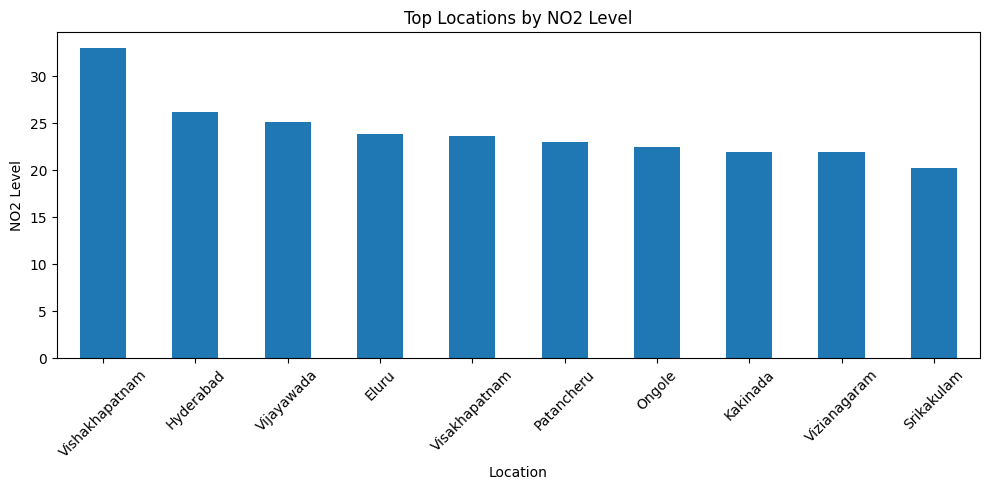

In [12]:
if "state" in data.columns and "location" in data.columns:

    location_data = data.groupby(
        ["state", "location"]
    )[pollutants].mean()

    print(location_data.head(10))

    # Display first state's top locations
    selected_state = data["state"].dropna().iloc[0]

    selected_data = location_data.loc[selected_state]

    selected_data["no2"].sort_values(
        ascending=False
    ).head(10).plot(kind="bar", figsize=(10, 5))

    plt.title("Top Locations by NO2 Level")
    plt.xlabel("Location")
    plt.ylabel("NO2 Level")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

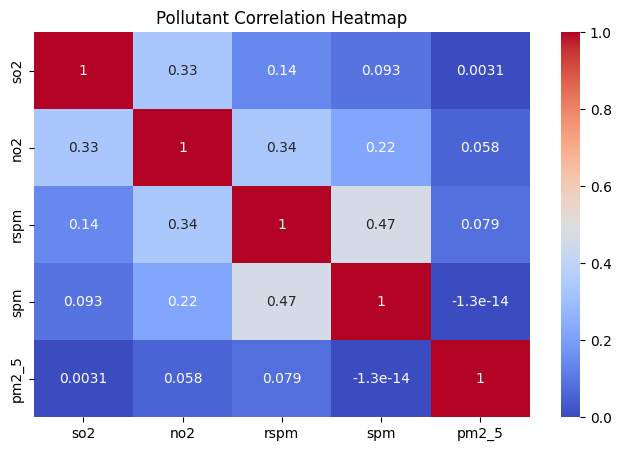

In [13]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    data[pollutants].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Pollutant Correlation Heatmap")
plt.show()

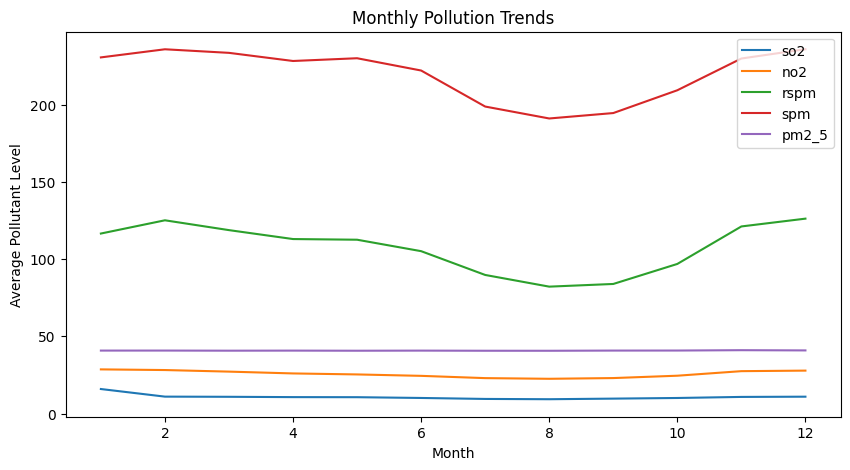

In [14]:
if "date" in data.columns:

    data["month"] = data["date"].dt.month

    monthly_data = data.groupby("month")[pollutants].mean()

    monthly_data.plot(figsize=(10, 5))

    plt.title("Monthly Pollution Trends")
    plt.xlabel("Month")
    plt.ylabel("Average Pollutant Level")
    plt.show()

else:
    print("Date column not available for monthly analysis.")

In [15]:
data.to_csv("Cleaned_AQI_Data.csv", index=False)

print("Cleaned AQI dataset saved successfully!")

Cleaned AQI dataset saved successfully!
